In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
import datetime
import glob

import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import matplotlib.ticker as ticker

from dask.diagnostics import ProgressBar
import dask.array as da

import os
os.chdir('/jetfs/home/psplechtna/msc_thesis/analysis/')

from utils import *

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
run='oper/1991'

In [4]:
# define flexpart output file path
path = '/jetfs/scratch/psplechtna/flexpart_output/'+run+'/'
filename_gridded = glob.glob(os.path.join(path, 'grid_time_*.nc'))[0]

# climatology path
path_clim = "/jetfs/scratch/psplechtna/thesisdata/mse_climatology_4.0/"
filename_clim = "mse_hourly_climatology.zarr"

# partinit file - diagnostics at time of particle release
filename_partinit = glob.glob(os.path.join(path, 'partinit_*.nc'))[0]

# pre-saved data from pre-processing
path_pre = '/jetfs/scratch/psplechtna/flexpart_output/'+run+'/processed_data/'

filename_lh = 'lh_50.zarr'
filename_sh = 'sh_50.zarr'
filename_tot = 'total_mse.zarr'
filename_seas = 'season.zarr'

# initial conditions
filename_init_conds = 'initial_conditions.nc'

In [5]:
# load data sets
gridded = xr.open_dataset(filename_gridded, chunks={'time': 200})
partinit = xr.open_dataset(filename_partinit)

rel_lh = xr.open_mfdataset(path_pre+filename_lh, engine='zarr', concat_dim='time', combine='nested')
rel_sh = xr.open_mfdataset(path_pre+filename_sh, engine='zarr', concat_dim='time', combine='nested')

rel_tot = xr.open_mfdataset(path_pre+filename_tot, engine='zarr', concat_dim='time', combine='nested')
rel_seas = xr.open_mfdataset(path_pre+filename_seas, engine='zarr', concat_dim='time', combine='nested')

rel_init_conds = xr.open_dataset(path_pre+filename_init_conds)

clim = xr.open_mfdataset(path_clim+filename_clim, 
                             engine='zarr', concat_dim='time', combine='nested')

In [6]:
n = gridded.RELPART[0].values               # number of particles per release (need to be equal per release)
no_of_rel = len(gridded.numpoint)           # number of releases
len_of_sim = int((gridded.LAGE.values/(3600*24)).item())  # days

# define constants
Lv = 2.5e6
cp = 1005
g = 9.80655

In [7]:
# construct release dates
reldates=[]
for i in range(no_of_rel):
    reldates.append(pd.Timestamp(gridded.time[0].values + pd.Timedelta(hours=1) + 
                                 pd.Timedelta(gridded.RELSTART.values[i], unit='s')))

In [8]:
# start with non-time-integrated data
# sum over latitude/longitude
with ProgressBar():
    sum_rel_lh = rel_lh.sum(dim=['latitude', 'longitude']).isel(time=slice(None, None, -1)).load()
    sum_rel_sh = rel_sh.sum(dim=['latitude', 'longitude']).isel(time=slice(None, None, -1)).load()

[########################################] | 100% Completed | 18.70 s
[########################################] | 100% Completed | 18.21 s


In [9]:
with ProgressBar():
    rel_tot = rel_tot.isel(time=slice(None, None, -1)).load()
    rel_seas = rel_seas.isel(time=slice(None, None, -1)).load()

[########################################] | 100% Completed | 14.86 s
[########################################] | 100% Completed | 14.72 s


In [51]:
# separate rel_lh/rel_sh into releases and obtain time series as in particle method
d_per_rel_lh = []
for i in range(no_of_rel):
    d_per_rel_lh.append(sum_rel_lh.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))
per_rel_lh = [np.cumsum(d_per_rel_lh[i].lh_50) for i in range(no_of_rel)]
d_per_rel_sh = []
for i in range(no_of_rel):
    d_per_rel_sh.append(sum_rel_sh.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))
per_rel_sh = [np.cumsum(d_per_rel_sh[i].sh_50) for i in range(no_of_rel)]

d_per_rel_seas = []
for i in range(no_of_rel):
    d_per_rel_seas.append(rel_seas.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))
per_rel_seas = [np.cumsum(d_per_rel_seas[i].season) for i in range(no_of_rel)]

d_per_rel_tot = []
for i in range(no_of_rel):
    d_per_rel_tot.append(rel_tot.total.sel(pointspec=i).sel
                      (time=slice((reldates[i]-datetime.timedelta(days=len_of_sim)), 
                                  (reldates[i]-datetime.timedelta(hours=1)))))

In [62]:
d_per_rel_tot[16]

<xarray.DataArray 'total' (time: 360)> Size: 1kB
array([296136.2 , 296128.06, 296105.78, 296129.2 , 296136.62, 296186.16,
       296178.16, 296144.84, 296183.34, 296249.44, 296119.22, 296186.84,
       296188.97, 296150.8 , 296131.4 , 296098.75, 296079.6 , 296023.12,
       296002.38, 295973.44, 295961.53, 295944.06, 295872.28, 295852.94,
       295842.38, 295844.22, 295845.94, 295824.8 , 295824.25, 295835.75,
       295846.12, 295858.4 , 295851.2 , 295849.44, 295767.72, 295753.84,
       295712.7 , 295685.22, 295644.97, 295636.28, 295588.16, 295543.94,
       295511.47, 295463.56, 295428.34, 295424.22, 295362.06, 295308.72,
       295306.9 , 295308.72, 295269.62, 295227.34, 295220.7 , 295224.22,
       295209.47, 295256.97, 295303.53, 295260.78, 295245.53, 295266.6 ,
       295256.94, 295276.62, 295270.5 , 295221.6 , 295231.97, 295257.88,
       295238.53, 295270.6 , 295253.34, 295280.72, 295225.66, 295210.66,
       295230.16, 295272.2 , 295321.72, 295373.06, 295411.88, 295482.4 ,
       295545.88, 295623.94, 295673.06, 295708.1 , 295700.38, 295697.44,
       295705.44, 295732.44, 295718.1 , 295721.1 , 295654.88, 295598.78,
       295653.78, 295674.03, 295601.88, 295614.56, 295405.2 , 295327.97,
       295353.84, 295329.3 , 295407.2 , 295537.34, 295708.28, 295861.34,
       295969.75, 296046.75, 296113.16, 296153.6 , 296144.75, 296199.53,
       296228.22, 296253.4 , 296244.97, 296235.12, 296204.9 , 296184.53,
       296172.8 , 296173.4 , 296152.6 , 296148.22, 296050.75, 296042.38,
...
       295635.06, 295641.38, 295633.1 , 295606.1 , 295614.66, 295553.22,
       295476.4 , 295382.7 , 295272.38, 295149.97, 295021.16, 294888.62,
       294757.62, 294635.  , 294527.78, 294424.97, 294275.53, 294208.2 ,
       294163.78, 294137.34, 294128.94, 294129.38, 294140.44, 294153.66,
       294154.78, 294147.47, 294130.94, 294104.22, 294124.78, 294071.66,
       294010.28, 293937.56, 293853.3 , 293768.06, 293683.66, 293599.03,
       293524.12, 293464.88, 293418.16, 293381.6 , 293343.72, 293323.5 ,
       293309.1 , 293290.  , 293272.5 , 293255.94, 293236.9 , 293215.9 ,
       293190.16, 293156.34, 293110.6 , 293054.38, 293064.75, 292979.53,
       292882.25, 292776.22, 292668.1 , 292553.3 , 292438.38, 292319.8 ,
       292205.2 , 292085.72, 291949.38, 291807.25, 291762.12, 291610.2 ,
       291489.75, 291394.7 , 291301.4 , 291190.72, 291079.06, 290942.66,
       290780.66, 290591.94, 290390.25, 290188.75, 290189.5 , 290038.7 ,
       289932.84, 289856.47, 289820.16, 289811.7 , 289810.  , 289818.06,
       289852.97, 289918.62, 290013.53, 290125.3 , 290396.84, 290524.94,
       290625.78, 290710.78, 290778.62, 290845.97, 290902.16, 290923.97,
       290903.75, 290827.75, 290697.44, 290533.78, 290405.47, 290255.9 ,
       290113.1 , 289958.66, 289801.34, 289639.53, 289479.56, 289337.22,
       289230.53, 289129.75, 289012.12, 288860.7 , 288722.47, 288416.38],
      dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 3kB 1991-06-18T12:00:00 ... 1991-07-03T1...
    dayofyear  (time) int32 1kB 169 169 169 169 169 169 ... 184 184 184 184 184
    hour       (time) int64 3kB 12 13 14 15 16 17 18 19 20 ... 4 5 6 7 8 9 10 11

In [49]:
d_per_rel_lh = [d_per_rel_lh[i] for i in range(no_of_rel)]
d_per_rel_sh = [d_per_rel_sh[i] for i in range(no_of_rel)]

# different handling for clim data
d_per_rel_seas = [d_per_rel_seas[i].season for i in range(no_of_rel)]
d_per_rel_tot = [-d_per_rel_tot[i].differentiate('time')*1e9*3600 for i in range(no_of_rel)]

In [12]:
d_per_rel_adv = [d_per_rel_tot[i] - d_per_rel_seas[i] for i in range(no_of_rel)]

In [13]:
#per_rel_tot = [np.cumsum(d_per_rel_tot[i]) for i in range(no_of_rel)]
per_rel_adv = [np.cumsum(d_per_rel_adv[i]) for i in range(no_of_rel)]

In [14]:
int_flux_lh = [lh[-1] for lh in per_rel_lh]
int_flux_sh = [sh[-1] for sh in per_rel_sh]

int_seas = [se[-1] for se in per_rel_seas]
int_adv = [adv[-1] for adv in per_rel_adv]
#int_tot_clim = [tt[-1] for tt in per_rel_tot]

In [15]:
np.max(d_per_rel_tot[6])

<xarray.DataArray 'total' ()> Size: 4B
array(635.0469, dtype=float32)

In [16]:
x = np.arange(-360,0,1)

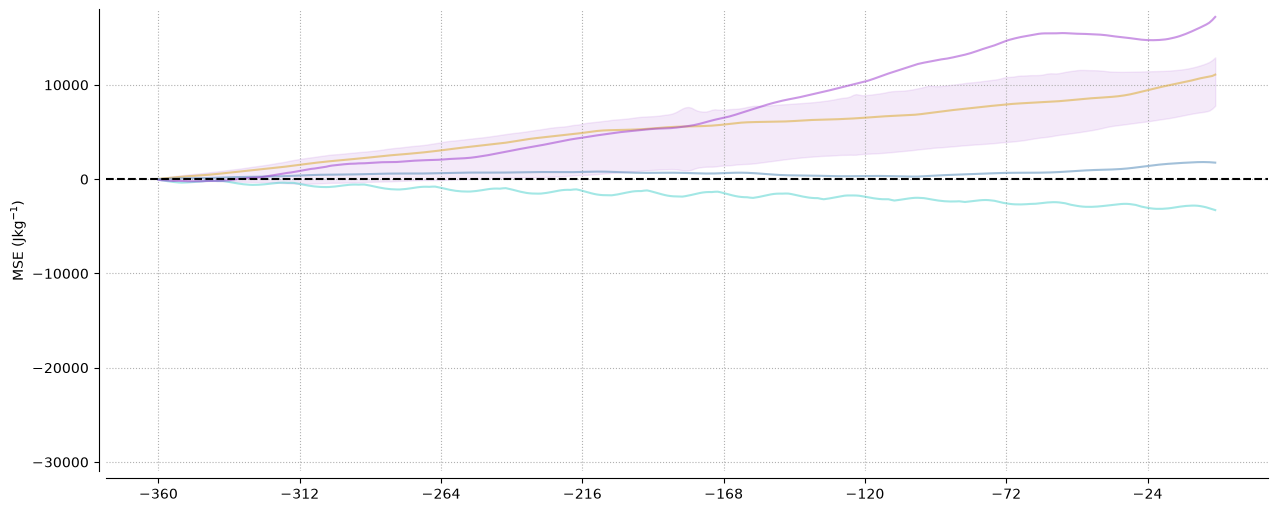

In [42]:
# for a single release
j=14
fig, ax = plt.subplots(1, 1, figsize=(15,6))

lh_flux, = ax.plot(x, per_rel_lh[j], color='goldenrod',
                   linestyle='-', alpha=0.5, label='LH term from sfc fluxes')
sh_flux, = ax.plot(x, per_rel_sh[j], color='steelblue',
                   linestyle='-', alpha=0.5, label='SH term from sfc fluxes')

se, = ax.plot(x, per_rel_seas[j], color='mediumturquoise',
                   linestyle='-', alpha=0.5, label='Seasonality')

adv, = ax.plot(x, per_rel_adv[j], color='darkorchid',
                   linestyle='-', alpha=0.5, label='Aadvection')
ax.fill_between(x, np.array(per_rel_adv).mean(axis=0) - np.array(per_rel_adv).std(axis=0),
                np.array(per_rel_adv).mean(axis=0) + np.array(per_rel_adv).std(axis=0), color='darkorchid', alpha=0.1) 

#calc, = ax.plot(x, per_rel_sw[j] + per_rel_lw[j]+ per_rel_sh[j] + per_rel_lh[j], 
#                color='grey', linestyle='--', label='Calculated')

ax.set_ylabel('MSE (Jkg$^{-1}$)')

# make it prettier
ax.grid(linestyle=':')
ax.axhline(0, linestyle='--', color='k')

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.set_xticks(x[0::48])

ax.set_ylim(-31000, 18000)

#fig.legend(handles = [season, adv, lh_flux, sh_flux, s_rad, l_rad, an_tot, calc], 
#           ncols=3, bbox_to_anchor=(0.3, 0.28, 0.4, 0.), frameon=True, framealpha=1)

#fig.savefig('rel_terms_temporal.png')
fig.show()

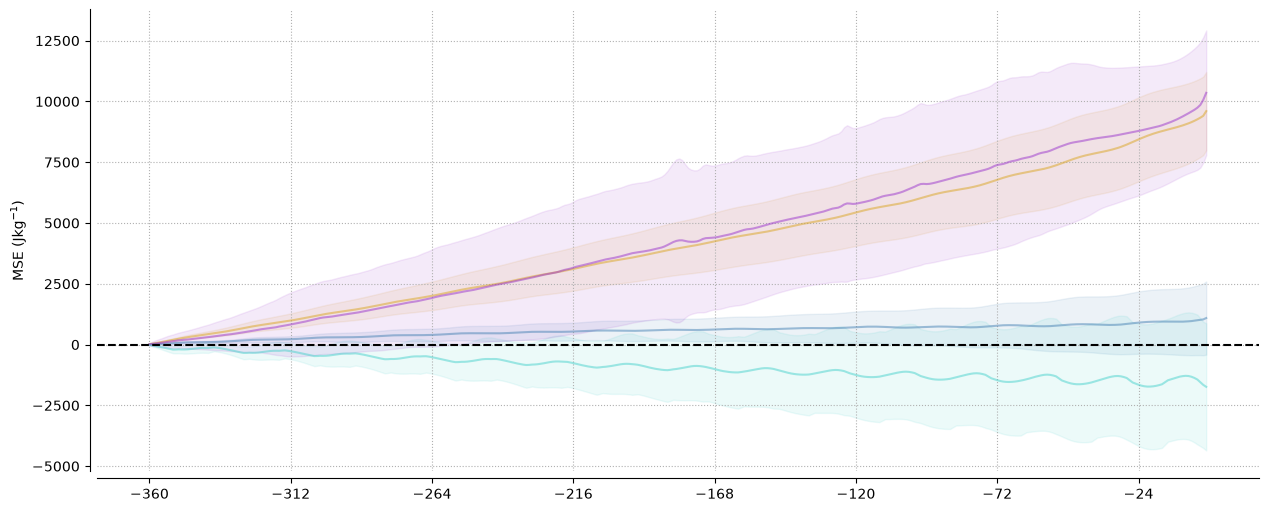

In [18]:
# on average over releases
fig, ax = plt.subplots(1, 1, figsize=(15,6))


lh_flux, = ax.plot(x, np.array(per_rel_lh).mean(axis=0), color='goldenrod',
                   linestyle='-', alpha=0.5, label='LH term from sfc fluxes')
ax.fill_between(x, np.array(per_rel_lh).mean(axis=0) - np.array(per_rel_lh).std(axis=0),
                np.array(per_rel_lh).mean(axis=0) + np.array(per_rel_lh).std(axis=0), color='goldenrod', alpha=0.1)
sh_flux, = ax.plot(x, np.array(per_rel_sh).mean(axis=0), color='steelblue',
                   linestyle='-', alpha=0.5, label='SH term from sfc fluxes')
ax.fill_between(x, np.array(per_rel_sh).mean(axis=0) - np.array(per_rel_sh).std(axis=0),
                np.array(per_rel_sh).mean(axis=0) + np.array(per_rel_sh).std(axis=0), color='steelblue', alpha=0.1) 


se, = ax.plot(x, np.array(per_rel_seas).mean(axis=0), color='mediumturquoise',
                   linestyle='-', alpha=0.5, label='Seasonality')
ax.fill_between(x, np.array(per_rel_seas).mean(axis=0) - np.array(per_rel_seas).std(axis=0),        
                np.array(per_rel_seas).mean(axis=0) + np.array(per_rel_seas).std(axis=0), color='mediumturquoise', alpha=0.1)

adv, = ax.plot(x, np.array(per_rel_adv).mean(axis=0), color='darkorchid',
                   linestyle='-', alpha=0.5, label='Aadvection')
ax.fill_between(x, np.array(per_rel_adv).mean(axis=0) - np.array(per_rel_adv).std(axis=0),
                np.array(per_rel_adv).mean(axis=0) + np.array(per_rel_adv).std(axis=0), color='darkorchid', alpha=0.1)  

#calc, = ax.plot(x, per_rel_sw[j] + per_rel_lw[j]+ per_rel_sh[j] + per_rel_lh[j], 
#                color='grey', linestyle='--', label='Calculated')

ax.set_ylabel('MSE (Jkg$^{-1}$)')

# make it prettier
ax.grid(linestyle=':')
ax.axhline(0, linestyle='--', color='k')

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.set_xticks(x[0::48])

#fig.legend(handles = [season, adv, lh_flux, sh_flux, s_rad, l_rad, an_tot, calc], 
#           ncols=3, bbox_to_anchor=(0.3, 0.28, 0.4, 0.), frameon=True, framealpha=1)

#fig.savefig('rel_terms_temporal.png')
fig.show()

### initial conds

In [19]:
# select initial condition data
init_per_release = rel_init_conds.sel(component='MSE')['grid_normalized_Jkg'].values
init_anomaly = rel_init_conds['init_anom'].values

### diagnose

In [20]:
partinit['amsl'] = partinit['to'] + partinit['z']

In [21]:
partinit['mse'] = partinit['T'] * cp + partinit['sh'] * Lv + partinit['amsl'] * g

In [22]:
diagnosed_partinit = [partinit['mse'].sel(particle=slice(rel*n+1, rel*n+n)).mean(dim='particle') for rel in range(no_of_rel)][::-1]

### split diagnose in climatology and anomaly

In [23]:
# shift longitude of climatology values into 0-360 range (from -180 - 180)
clim = clim.assign_coords(longitude=(clim['longitude'] % 360)).sortby('longitude')

# what is being done here?
clim = clim.squeeze('time', drop=True)

In [24]:
# ----------------------------------------------------------------------
# 1. Prepare the climatology
# ----------------------------------------------------------------------
buffer = 2          # degrees lat/lon
z_buffer = 500      # metres

lon_p = (partinit['lon'] % 360).values
lat_p = partinit['lat'].values
z_p   = partinit['amsl'].values


# crop to the trajectory extent (clim latitudes are descending)
clim_c = clim['mse'].sel(
    latitude=slice(lat_p.max() + buffer, lat_p.min() - buffer),
    longitude=slice(lon_p.min() - buffer, lon_p.max() + buffer),
    height=slice(max(z_p.min() - z_buffer, 0), z_p.max() + z_buffer),
)

# interpn wants ascending coords, and a fixed dim order
clim_c = (
    clim_c.sortby(['dayofyear', 'hour', 'height', 'latitude', 'longitude'])
          .transpose('dayofyear', 'hour', 'height', 'latitude', 'longitude')
          .load()   # cropped clim is small (a few hundred MB at most)
)

# merge (dayofyear, hour) into one continuous time axis in "hours since Jan 1"
doy_vals  = clim_c['dayofyear'].values
hour_vals = clim_c['hour'].values
n_doy, n_hr = len(doy_vals), len(hour_vals)

t_clim = ((doy_vals[:, None] - 1) * 24 + hour_vals[None, :]).ravel().astype('float64')
period = float(doy_vals.max() * 24)   # 8784 for 366 days, 8760 for 365

data = clim_c.values.reshape(n_doy * n_hr, *clim_c.shape[2:])

# pad one step on each side so interpolation wraps around the year boundary
data_pad = np.concatenate([data[-1:], data, data[:1]], axis=0)
t_pad = np.concatenate([[t_clim[-1] - period], t_clim, [t_clim[0] + period]])

clim_t = xr.DataArray(
    data_pad,
    dims=('t', 'height', 'latitude', 'longitude'),
    coords={
        't': t_pad,
        'height': clim_c['height'].values,
        'latitude': clim_c['latitude'].values,
        'longitude': clim_c['longitude'].values,
    },
    name='mse',
)

# ----------------------------------------------------------------------
# 2. Build the particle-time axis on the same scale
# ----------------------------------------------------------------------
time = partinit['time'].dt
t_p = ((time.dayofyear.values - 1) * 24
       + time.hour.values
       + time.minute.values / 60
       + time.second.values / 3600).astype('float64')

# ----------------------------------------------------------------------
# 3. Interpolate (pointwise: all indexers share the 'particle' dim)
# ----------------------------------------------------------------------
def pt(values):
    return xr.DataArray(values, dims='particle')

mse_clim_diag = clim_t.interp(
    t=pt(t_p),
    height=pt(z_p),
    latitude=pt(lat_p),
    longitude=pt(lon_p),
    kwargs={"fill_value": None},   # linear extrapolation outside the grid
)

# ----------------------------------------------------------------------
# 4. Attach to trajectory data and compute anomaly
# ----------------------------------------------------------------------
partinit['mse_clim'] = ('particle', mse_clim_diag.values.astype('float32'))
partinit['mse_anomaly'] = partinit['mse'] - partinit['mse_clim']

# sanity check
print('NaNs in mse_clim:', int(partinit['mse_clim'].isnull().sum().item()))
print(partinit[['mse', 'mse_clim', 'mse_anomaly']].to_dataframe().describe())

NaNs in mse_clim: 0
                mse      mse_clim   mse_anomaly
count  9.200000e+06  9.200000e+06  9.200000e+06
mean   2.872870e+05  2.879345e+05 -6.474979e+02
std    3.808509e+03  3.165544e+03  2.513618e+03
min    2.781111e+05  2.798528e+05 -1.089097e+04
25%    2.846903e+05  2.856968e+05 -2.257312e+03
50%    2.869748e+05  2.878841e+05 -6.776562e+02
75%    2.898071e+05  2.902150e+05  7.972812e+02
max    3.006200e+05  2.988048e+05  1.057522e+04


In [25]:
diagnosed_partinit_clim = [partinit['mse_clim'].sel(particle=slice(rel*n+1, rel*n+n)).
                      mean(dim='particle') for rel in range(no_of_rel)][::-1]
diagnosed_partinit_anomaly = [partinit['mse_anomaly'].sel(particle=slice(rel*n+1, rel*n+n)).
                      mean(dim='particle') for rel in range(no_of_rel)][::-1]

### calculate

In [26]:
# save data
arrays = {
    'diag': diagnosed_partinit,
    'diag_anomaly': diagnosed_partinit_anomaly,
    'init': init_per_release,
    'init_anomaly': init_anomaly,
    'flux_lh': int_flux_lh,
    'flux_sh': int_flux_sh,
    'advection': int_adv,
    'seasonality': int_seas
}

ds_timeseries = xr.Dataset(
    {k: ('release_date', np.asarray(v)) for k, v in arrays.items()},
    coords={'release_date': reldates},
)

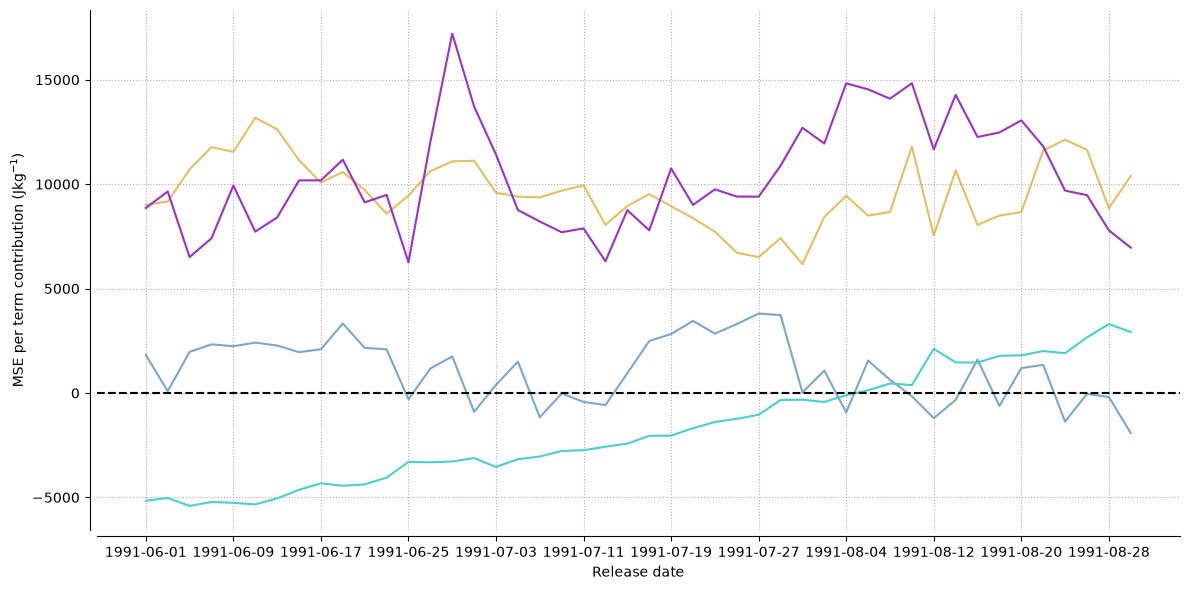

In [27]:
# single terms
xes = ds_timeseries.release_date
fig, ax = plt.subplots(1, 1, figsize=(12,6))

int_f_lh, = ax.plot(xes, ds_timeseries.flux_lh, color='goldenrod', alpha=0.7, 
                    linestyle='-', label='LH term from sfc fluxes')
int_f_sh, = ax.plot(xes, ds_timeseries.flux_sh, color='steelblue', alpha=0.7, 
                    linestyle='-', label='LH term from sfc fluxes')

int_adve, = ax.plot(xes, ds_timeseries.advection, color='darkorchid', label='Advection')
int_s, = ax.plot(xes, ds_timeseries.seasonality, color='mediumturquoise', label='Seasonality')
#int_rad, = ax.plot(x, data.all_rad, color='tan', label='Total radiative cooling')

ax.set_ylabel('MSE per term contribution (Jkg$^{-1}$)')
ax.set_xticks(xes[::4])
ax.set_xlabel('Release date')

#ax.set_ylim(-46000, 22000)
#ax.set_yticks(np.arange(-45000, 21000, 5000))

ax.axhline(0, linestyle='--', color='k')

# make prettier
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.grid(linestyle=':')

fig.tight_layout()
#fig.savefig('allterms.png')

In [28]:
# initial and diagnosed climatological values
init_clim = ds_timeseries.init - ds_timeseries.init_anomaly
diag_clim = ds_timeseries.diag - ds_timeseries.diag_anomaly

In [37]:
# residual from advection and seasonality terms from the calculation
clim_res = (init_clim - diag_clim) - (ds_timeseries.seasonality + ds_timeseries.advection)

In [58]:
init_clim[12]

<xarray.DataArray ()> Size: 8B
array(297927.81044186)
Coordinates:
    release_date  datetime64[ns] 8B 1991-06-25T12:00:00

In [46]:
diag_clim[12]

<xarray.DataArray ()> Size: 4B
array(286980.28, dtype=float32)
Coordinates:
    release_date  datetime64[ns] 8B 1991-06-25T12:00:00

In [38]:
clim_res

<xarray.DataArray (release_date: 46)> Size: 368B
array([ 7.03729523e+01,  1.48588458e+02,  5.54656319e+02,  1.42972624e+02,
       -6.20173008e-01, -9.38977057e+00, -9.32572898e+01, -9.73791645e+01,
       -1.28083542e+02, -6.33623751e+01,  3.35622173e+02,  1.24812602e+02,
        7.99093202e+03,  2.25036782e+03,  1.22578665e+02, -5.19985849e+01,
       -3.46998135e+00,  1.30870427e+02,  4.05496271e+02,  1.96005014e+02,
        1.79362813e+02,  1.17552939e+03,  2.26147526e+02, -1.86146150e+02,
       -9.41181002e+01,  1.67651898e+02, -9.74670894e+01, -1.13161233e+02,
       -3.28074792e+01, -1.71218471e+02,  9.51321432e+01,  1.65445291e+03,
        1.28966818e+02, -2.13776188e+01,  1.04770087e+02, -2.18039173e+02,
       -1.48170607e+02, -1.99436291e+02,  1.03715497e+02,  2.01552616e+01,
       -2.61558496e+02,  5.66757462e+02,  2.94568011e+03, -7.10809891e+01,
        3.84970507e+02,  7.81843538e+02])
Coordinates:
  * release_date  (release_date) datetime64[ns] 368B 1991-06-01T12:00:00 ... ...

In [34]:
clim_res[12]

<xarray.DataArray ()> Size: 8B
array(7990.9320239)
Coordinates:
    release_date  datetime64[ns] 8B 1991-06-25T12:00:00

In [32]:
ds_timeseries

<xarray.Dataset> Size: 2kB
Dimensions:       (release_date: 46)
Coordinates:
  * release_date  (release_date) datetime64[ns] 368B 1991-06-01T12:00:00 ... ...
Data variables:
    diag          (release_date) float32 184B 2.799e+05 2.807e+05 ... 2.833e+05
    diag_anomaly  (release_date) float32 184B -1.965e+03 ... -4.082e+03
    init          (release_date) float64 368B 2.838e+05 2.86e+05 ... 2.967e+05
    init_anomaly  (release_date) float64 368B -1.794e+03 ... -1.282e+03
    flux_lh       (release_date) float32 184B 9.008e+03 9.165e+03 ... 1.039e+04
    flux_sh       (release_date) float32 184B 1.829e+03 84.34 ... -1.92e+03
    advection     (release_date) float32 184B 8.855e+03 9.65e+03 ... 6.96e+03
    seasonality   (release_date) float32 184B -5.162e+03 -5.027e+03 ... 2.92e+03

In [33]:
#ds_timeseries.to_netcdf('/jetfs/scratch/psplechtna/thesisdata/' + run + '_tsr.nc')